In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_style("whitegrid")
os.makedirs("Images", exist_ok=True)   # charts are saved here for GitHub
RANDOM_STATE = 42

Upload and load the data

In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("johnsmith88/heart-disease-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'heart-disease-dataset' dataset.
Path to dataset files: /kaggle/input/heart-disease-dataset


Inspect

In [4]:
import os

# List the files in the downloaded path to locate the CSV file
files = os.listdir(path)
print("Files in dataset path:", files)

# Load the dataset into df (assuming heart.csv or similar is present)
csv_file = [f for f in files if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))

print("Shape:", df.shape)
df.info()
df.describe().T

Files in dataset path: ['heart.csv']
Shape: (1025, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


Cleaning, part 1 (missing values and placeholders)

In [6]:
print("Missing values per column:\n", df.isnull().sum())
print("\nca value counts:\n", df["ca"].value_counts().sort_index())
print("\nthal value counts:\n", df["thal"].value_counts().sort_index())

Missing values per column:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

ca value counts:
 ca
0    578
1    226
2    134
3     69
4     18
Name: count, dtype: int64

thal value counts:
 thal
0      7
1     64
2    544
3    410
Name: count, dtype: int64


Cleaning, part 2 (duplicates)

In [7]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

Duplicate rows: 723
Shape after dropping duplicates: (302, 14)


Cleaning, part 3 (placeholders and plausibility)

In [8]:
# In this dataset ca=4 and thal=0 actually mean "missing"
df["ca"] = df["ca"].replace(4, np.nan)
df["thal"] = df["thal"].replace(0, np.nan)
print("Placeholders found as NaN:\n", df[["ca", "thal"]].isnull().sum())

for col in ["ca", "thal"]:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df[["age", "trestbps", "chol", "thalach", "oldpeak"]].agg(["min", "max"]))
print("\nTarget balance:\n", df["target"].value_counts())

Placeholders found as NaN:
 ca      4
thal    2
dtype: int64
     age  trestbps  chol  thalach  oldpeak
min   29        94   126       71      0.0
max   77       200   564      202      6.2

Target balance:
 target
1    164
0    138
Name: count, dtype: int64


EDA chart 1 (disease rate by sex and chest pain)

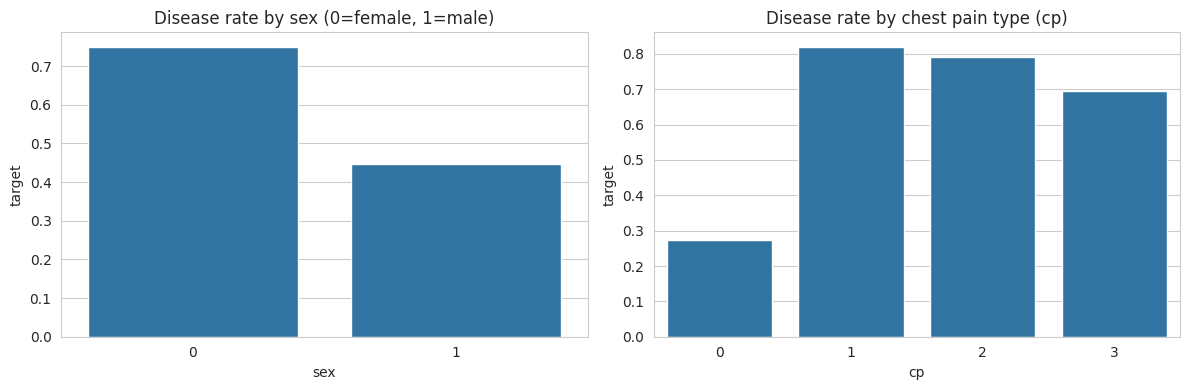

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x="sex", y="target", data=df, ax=ax[0], errorbar=None)
ax[0].set_title("Disease rate by sex (0=female, 1=male)")
sns.barplot(x="cp", y="target", data=df, ax=ax[1], errorbar=None)
ax[1].set_title("Disease rate by chest pain type (cp)")
plt.tight_layout()
plt.savefig("Images/01_disease_rate_sex_cp.png", dpi=150)
plt.show()

EDA chart 2 (max heart rate by target)

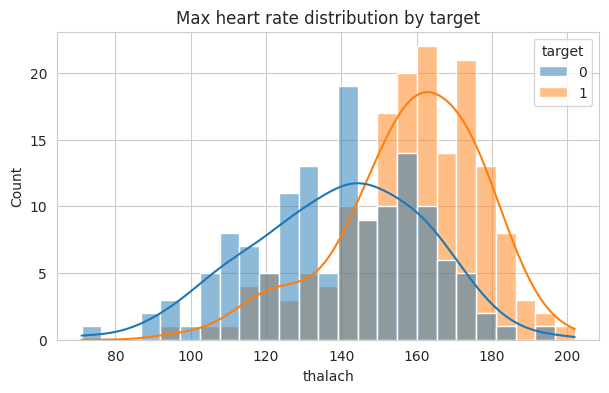

In [10]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="thalach", hue="target", kde=True, bins=25)
plt.title("Max heart rate distribution by target")
plt.savefig("Images/02_thalach_by_target.png", dpi=150)
plt.show()

EDA chart 3 (correlation heatmap)

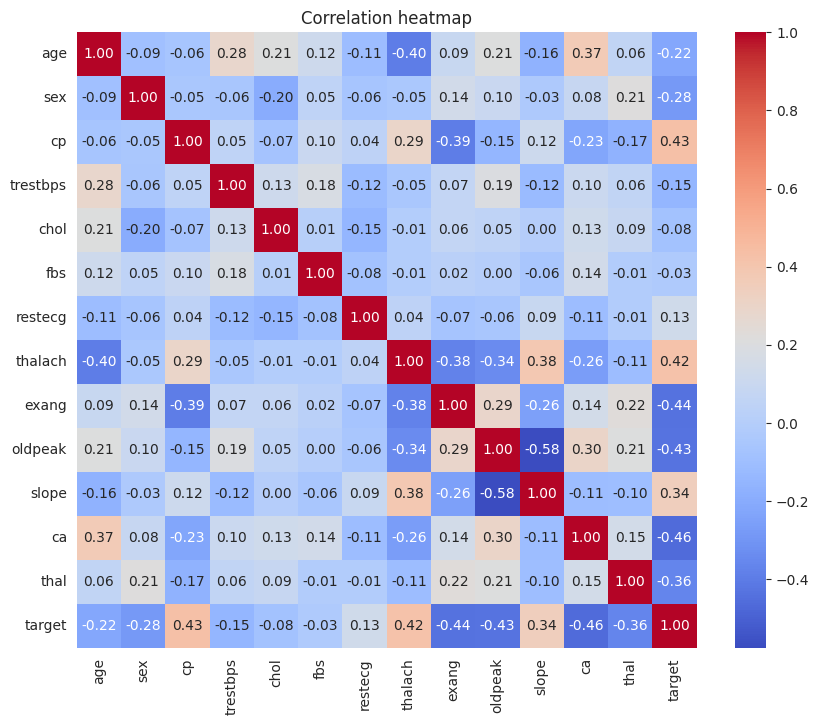

cp          0.432080
thalach     0.419955
slope       0.343940
restecg     0.134874
fbs        -0.026826
chol       -0.081437
trestbps   -0.146269
age        -0.221476
sex        -0.283609
thal       -0.362313
oldpeak    -0.429146
exang      -0.435601
ca         -0.463886
Name: target, dtype: float64


In [11]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.savefig("Images/03_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.corr()["target"].drop("target").sort_values(ascending=False))

EDA chart 4 (oldpeak vs target)

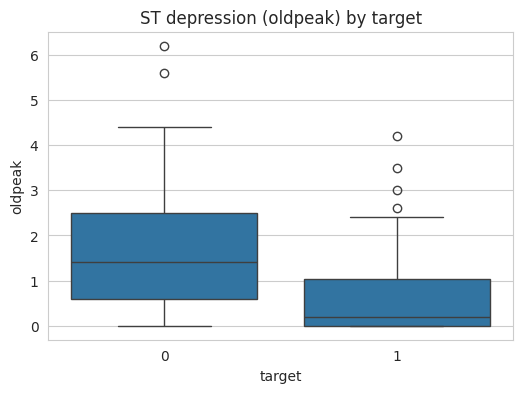

In [12]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="target", y="oldpeak", data=df)
plt.title("ST depression (oldpeak) by target")
plt.savefig("Images/04_oldpeak_by_target.png", dpi=150)
plt.show()

EDA chart 5 (age by target)

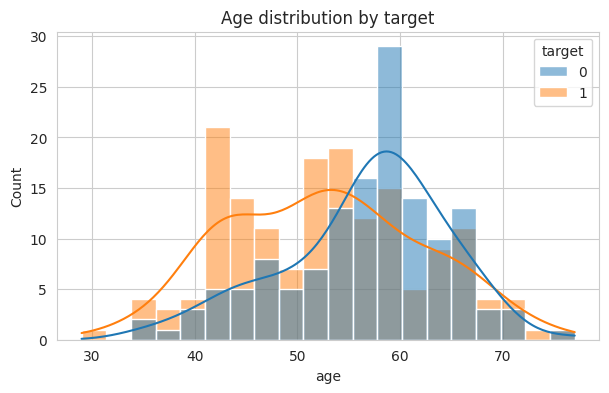

In [13]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="age", hue="target", kde=True, bins=20)
plt.title("Age distribution by target")
plt.savefig("Images/05_age_by_target.png", dpi=150)
plt.show()

Feature engineering (one-hot encoding)

In [14]:
cat_cols = ["cp", "restecg", "slope", "thal"]
df_enc = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print(df_enc.shape)
df_enc.head()

(302, 19)


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,target,cp_1,cp_2,cp_3,restecg_1,restecg_2,slope_1,slope_2,thal_2.0,thal_3.0
0,52,1,125,212,0,168,0,1.0,2.0,0,0,0,0,1,0,0,1,0,1
1,53,1,140,203,1,155,1,3.1,0.0,0,0,0,0,0,0,0,0,0,1
2,70,1,145,174,0,125,1,2.6,0.0,0,0,0,0,1,0,0,0,0,1
3,61,1,148,203,0,161,0,0.0,1.0,0,0,0,0,1,0,0,1,0,1
4,62,0,138,294,1,106,0,1.9,3.0,0,0,0,0,1,0,1,0,1,0


Optional age-group feature (exploratory only)

In [15]:
df["age_group"] = (df["age"] // 10 * 10).astype(int)
df.groupby("age_group")["target"].mean()

,target
age_group,
20,1.000000
30,0.714286
40,0.694444
50,0.520000
60,0.400000
70,0.600000


Train/test split and scaling

In [16]:
X = df_enc.drop("target", axis=1)
y = df_enc["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Fit the scaler on TRAIN only, then apply it to test (avoids data leakage)
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (241, 18)  Test: (61, 18)


Train the model

In [18]:
model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

Metrics

In [19]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
}
for k, v in metrics.items():
    print(f"{k:10s}: {v:.3f}")

print("\n", classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

Accuracy  : 0.852
Precision : 0.875
Recall    : 0.848
F1        : 0.862
ROC-AUC   : 0.907

               precision    recall  f1-score   support

  No disease       0.83      0.86      0.84        28
     Disease       0.88      0.85      0.86        33

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61



Confusion matrix and ROC curve

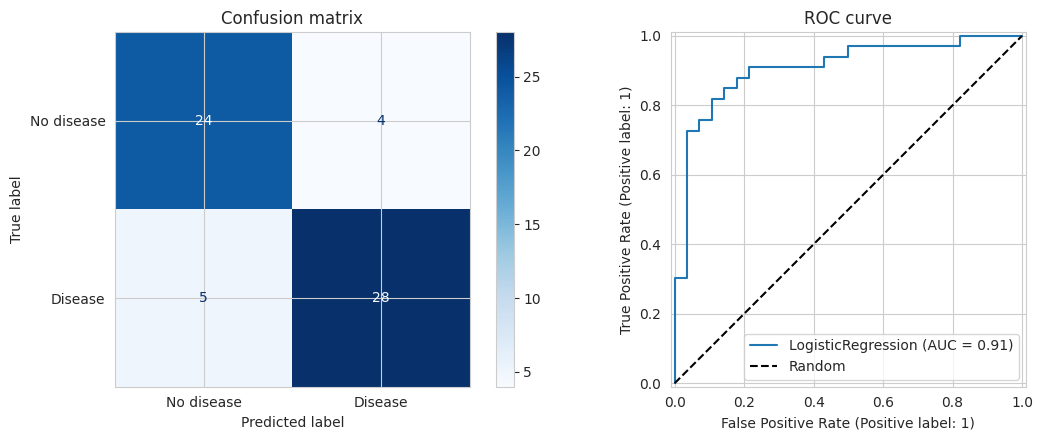

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                        display_labels=["No disease", "Disease"],
                                        cmap="Blues", ax=ax[0])
ax[0].set_title("Confusion matrix")
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--", label="Random")
ax[1].set_title("ROC curve")
ax[1].legend()
plt.tight_layout()
plt.savefig("Images/06_confusion_matrix_roc.png", dpi=150)
plt.show()

Coefficients (top health indicators)

,feature,coefficient
10,cp_2,1.467654
11,cp_3,1.296133
1,sex,-1.286788
8,ca,-1.195442
6,exang,-0.976511
17,thal_3.0,-0.946619
5,thalach,0.709212
9,cp_1,0.514877
14,slope_1,-0.448089
15,slope_2,0.411781


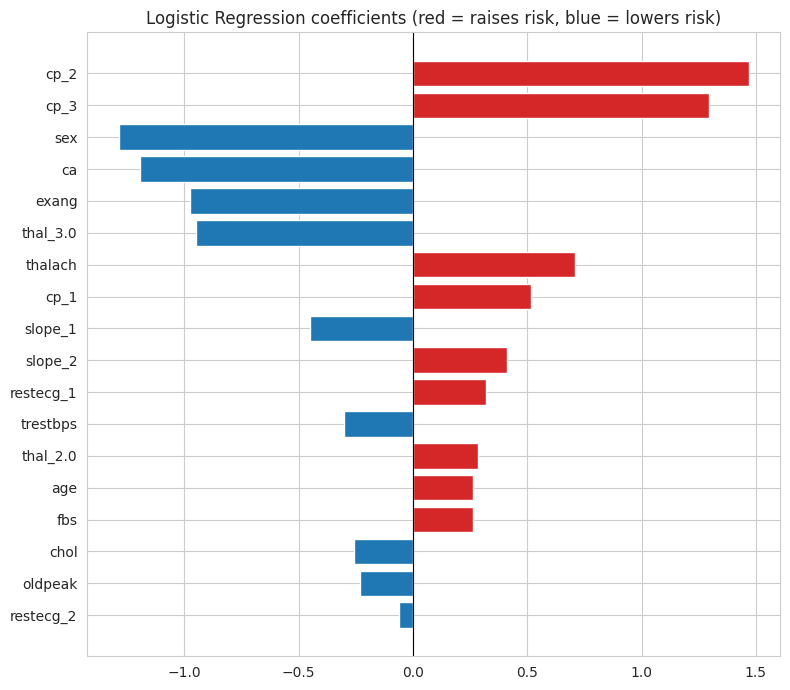

In [21]:
coef = pd.DataFrame({"feature": X.columns, "coefficient": model.coef_[0]})
coef["abs"] = coef["coefficient"].abs()
coef = coef.sort_values("abs", ascending=False).drop(columns="abs")
display(coef)

plt.figure(figsize=(8, 7))
colors = ["tab:red" if c > 0 else "tab:blue" for c in coef["coefficient"][::-1]]
plt.barh(coef["feature"][::-1], coef["coefficient"][::-1], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Logistic Regression coefficients (red = raises risk, blue = lowers risk)")
plt.tight_layout()
plt.savefig("Images/07_coefficients.png", dpi=150)
plt.show()

Why recall matters (threshold experiment)

In [23]:
for t in [0.5, 0.4, 0.3]:
    pred_t = (y_proba >= t).astype(int)
    print(f"threshold={t}: recall={recall_score(y_test, pred_t):.3f}  "
          f"precision={precision_score(y_test, pred_t):.3f}  "
          f"accuracy={accuracy_score(y_test, pred_t):.3f}")

threshold=0.5: recall=0.848  precision=0.875  accuracy=0.852
threshold=0.4: recall=0.879  precision=0.829  accuracy=0.836
threshold=0.3: recall=0.909  precision=0.811  accuracy=0.836


Download charts for GitHub

In [24]:
!zip -r Images.zip Images
from google.colab import files
files.download("Images.zip")

  adding: Images/ (stored 0%)
  adding: Images/04_oldpeak_by_target.png (deflated 20%)
  adding: Images/03_correlation_heatmap.png (deflated 5%)
  adding: Images/06_confusion_matrix_roc.png (deflated 16%)
  adding: Images/01_disease_rate_sex_cp.png (deflated 24%)
  adding: Images/02_thalach_by_target.png (deflated 6%)
  adding: Images/05_age_by_target.png (deflated 7%)
  adding: Images/07_coefficients.png (deflated 24%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>